In [1]:
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/impport_packages.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/simulation_class.ipynb"    #import all necessary packages - numpy, pandas etc
%run "/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/simulation/interactive_jupyter_notebooks/simulation_prereqs/create_world.ipynb"

#### Set up sim essentials

The onlything modified here is the `run_simulation` function

Redifine `run simulation` without the rho and m subsets + proper seeding for replicates

In [3]:
def run_simulation(params):
    scenarios, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, only_genetics = params
    
    rho_m_alpha_beta = scenarios[0:4]
    env_states = scenarios[4:]
    
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    

    meanw = np.zeros(maxgen)
    meanmemory_g = np.zeros(maxgen)
    meanmemory_p= np.zeros(maxgen)
    meanneutral_g = np.zeros(maxgen)
    meanneutral_p = np.zeros(maxgen)
    mean_gen = np.zeros(maxgen)

    
    for t in range(0, (maxgen-1)):
        #if t%10 == 0:
        #    print(t)
        for d in range(0, nof_dimensions):
            N[:,dims['dev'][d]] = N[:,dims['pheno'][d]] - env_states[t]
            
        dist_from_optima = np.sqrt(np.sum(N[:,dims['dev']]**2, axis =1))
        
        #------distance correction ------
        def between_optima_dist(dims):
            multi_d_diff = np.ones(dims) - np.zeros(dims)
            
            return np.sqrt(np.sum(multi_d_diff**2))
        #-----------------------------
        normalised_dist = dist_from_optima/between_optima_dist(nof_dimensions) 
        
        W = np.exp((-normalised_dist**2)/ (2))
        
        
        meanw[t] = np.mean(W)    
    
        
        meanmemory_g[t] = np.mean(N[:, dims['memory']])  # the actual memory
        meanmemory_p[t] = np.mean(1/(1 + np.exp(-N[:,dims['memory']]))) #with the logistc correction
        
        meanneutral_g[t] = np.mean(N[:,dims['neutral']])
        meanneutral_p[t] = np.mean(1/(1 + np.exp(-N[:,dims['neutral']])))
        mean_gen[t] = np.mean(N[:,dims['geno']])
        

        
        #current gen offspring (the cube gets stored here per gen)
        
        offspring = np.zeros((popsize, dims['total_layers'])) # empty 3D matrix with dimensions of the cube
        
        #sample offspring for each scenario weighted by fitness
        
        
        parents_idx = np.random.choice(popsize, size=popsize, p = (W/np.sum(W)) )#pick #popsize sized random numbers
        offspring[:,:] = N[parents_idx, :] #similar to how it works in matlab
        
        mutate_memories = np.random.uniform(low=0, high=1, size= popsize) < mutrate[0]
        #mutate_neutral = np.random.uniform(low=0, high=1, size=popsize) < mutrate[0]
        mutate_geno = np.random.uniform(low=0, high=1, size=(popsize, nof_dimensions)) < mutrate[1]
        
        # adding a mutation of size mutsize[1], rate mutate_memories, to the epi-memory
        # the epignetic memory evolves; 
        
        offspring[:,dims['memory']] = (
                                offspring[:,dims['memory']] 
                                + mutate_memories * np.random.normal(0, mutsize[0], popsize)
        )
        
        # adding a mutation of size mutsize[1] (epi-mutation size), rate mutate_memories, to the neutral phenotype
        # the neutral trait recieves random mutation but is not implemented in the calculation for fitness; so is evolving neutrally
        offspring[:,dims['neutral']] = (
                                offspring[:,dims['neutral']]  
                                + mutate_memories * np.random.normal(0, mutsize[0], popsize)
        ) 
        
        # adding a mutation of size mutsize[2] (genetic mutation size), rate mutate_memories, to the genotype

        offspring[:,dims['geno']] = (
                            offspring[:,dims['geno']] 
                            + mutate_geno * np.random.normal(0, mutsize[1], size=(popsize, nof_dimensions) )
        )
        
        
        # Construct the phenotype
        if only_genetics :
            if t % 10000 == 0:
                print(f"Gen {t}: Running ONLY genetics mode")
            
            for i in range(0, nof_dimensions):
                offspring[:, dims['pheno'][i]] = (
                offspring[:, dims['geno'][i]]
                + np.random.normal(0, epsilon, size=popsize) )
        else:
            if t % 10000 == 0:
                print(f"Gen {t}: Running EPIGENETIC mode")
            
            for i in range(0, nof_dimensions):
                    offspring[:, dims['pheno'][i]] = (
                        offspring[:, dims['geno'][i]] #genotype
                        + np.random.normal(0, epsilon, size=popsize) # adding random noise (developemental noise, nromally distributed with epsilon variance)
                        + ((1 / (1 + np.exp(-offspring[:, dims['memory']]))) #phenotype version of the memory (y axis) 
                        * (N[parents_idx, dims['pheno'][i]] - N[parents_idx, dims['geno'][i]]))# adding the deviation -> read as weight (phenotypic component * deviation)
                    )
        N = offspring
        
        
    return {
        'rho_m_alpha_beta' :rho_m_alpha_beta, ## Make sure this is indented!!
        'maxgen_popsize': [maxgen,popsize],
        'meanw': meanw,
        'meanmemory_p': meanmemory_p,
        'meanneutral_p': meanneutral_p

        }
        

        
        

Model params

In [4]:
popsize = 5000

# Mutation rates: [epi-memory mutation rate, geno mutation rate]
mutrate = [0.001, 0.001]

# Mutation sizes: [epi-memory mutation size, geno mutation size]
mutsize = [1, 1]

epsilon = 0.05# phenotypic noise
                                 
initial_memory = 0

results_array = {}  ### DONT FORGET TO RUN BEFORE NEW PARAM CONDITIONS

mutrate[0]*mutsize[0]

maxgen = 50000




##### Define a constant unchanging envrionment with replicates

In [5]:
#Replicates = n_scenarios

# Then tile n_reps times to get the array for the replicates
n_reps = 100   # How many scenarios do you want? (also replicates)

Env = np.zeros((n_reps, maxgen), dtype=int) #same as hannas E()

nof_scenarios = np.shape(Env)[0]
print('nof_replicates:', n_reps) 

nof_replicates: 100


##### Define a sudden shift about midway 

In [6]:
prop = 7000
# Then tile n_reps times to get the array for the replicates
n_reps = 10  # How many scenarios do you want? (also replicates)
Env = np.concatenate([np.zeros((n_reps, prop), dtype=int), 
                      np.ones((n_reps, (maxgen-prop)), dtype=int)], 
                     axis=1)  # Join along time dimension
nof_scenarios = np.shape(Env)[0]
print('nof_replicates:', n_reps) 

nof_replicates: 10


#### Define stochastically changing environment

In [4]:
def create_world_single(rho,m, max_gen):

    # Define rho and m grid
    rho = rho
    m = m
    alpha = (1 - rho) * (1 - m)
    beta = (1 - rho) * m


    # Flatten and create DataFrame
    data_env = np.array([rho, m, alpha, beta])

    n_gen = max_gen


    opt = np.array([0, 1])

    Env = np.zeros(n_gen, dtype=int)
    p = np.random.uniform(0, 1, n_gen)

    for g in range(n_gen - 1):
        if p[g] < (alpha if Env[g] == 0 else beta):
            Env[g+1] = 1 - Env[g]  # Flip state
        else:
            Env[g+1] = Env[g]       # Stay same

    env_values = opt[Env] # final result

    
    rho_m_alpha_beta = data_env

    # Equilibrium stats
    return rho_m_alpha_beta, env_values

In [ ]:
rho_val_0, m_val_0 = 0.8, 0.99
rho_val_1, m_val_1 = 0.9,0.97
rho_val_2, m_val_2 = 0.99, 0.85


In [21]:
# First create single scenario,
rho_val_0 =0.01
m_val_0 =0.55

rho_m_alpha_beta_0, single_scenario_0 = create_world_single(rho =rho_val_0, m= m_val_0, max_gen= maxgen)  # Shape: (10000,)

# First create single scenario,
rho_val_1 =0.9
m_val_1 =0.75

rho_m_alpha_beta_1, single_scenario_1 = create_world_single(rho =rho_val_1, m= m_val_1, max_gen= maxgen)  # Shape: (10000,)

# First create single scenario,

rho_val_2 =0.99
m_val_2 =0.9

rho_m_alpha_beta_2, single_scenario_2 = create_world_single(rho =rho_val_2, m= m_val_2, max_gen= maxgen)  # Shape: (10000,)


# Then tile n_reps times to get the array for the replicates
n_reps = 10

Env_stoch = np.vstack([
    np.hstack((
        np.tile(rho_m_alpha_beta_0, (n_reps, 1)),  # Now (10, 10000)
        np.tile(single_scenario_0, (n_reps, 1))    # (10, 10000)
    )),
    np.hstack((
        np.tile(rho_m_alpha_beta_1, (n_reps, 1)),  # Same rho for scenario 1
        np.tile(single_scenario_1, (n_reps, 1))
    ))
    #np.hstack((
      #  np.tile(rho_m_alpha_beta_2, (n_reps, 1)),  # Same rho for scenario 1
       # np.tile(single_scenario_2, (n_reps, 1))
  #  ))
])

Env_stoch


array([[0.01  , 0.55  , 0.4455, ..., 1.    , 1.    , 0.    ],
       [0.01  , 0.55  , 0.4455, ..., 1.    , 1.    , 0.    ],
       [0.01  , 0.55  , 0.4455, ..., 1.    , 1.    , 0.    ],
       ...,
       [0.9   , 0.75  , 0.025 , ..., 0.    , 0.    , 0.    ],
       [0.9   , 0.75  , 0.025 , ..., 0.    , 0.    , 0.    ],
       [0.9   , 0.75  , 0.025 , ..., 0.    , 0.    , 0.    ]],
      shape=(20, 50004))

### Run the simulations parallely

Create `cube` to store results

##### Constant and sudden change settings

In [ ]:
onlygen = False

# Number of dimensions (can be 1 or more)
nof_dimensions = 10

# get the cube dimensions
dims = get_cube_dims(nof_dimensions)

#create the cube
N = create_cube(popsize, dims=dims, nof_dimensions=nof_dimensions, epsilon=epsilon, initial_memory=initial_memory)

print(N.shape)


### Define seed_array
seed_array = np.random.randint(0, 100000, n_reps)

if __name__ == '__main__':
    
    # Create all combinations of sigma_mut and sigma_alpha
    param_grid = [
        (scenario, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, False) #only genetics can either be True or false
        for scenario, seed in zip(Env[:,4:], seed_array) #where each row corresponds to one scenario
    ]

    num_cpus = 10
    
    with concurrent.futures.ProcessPoolExecutor(num_cpus) as executor: 
        results_array = list(executor.map(run_simulation, param_grid))

(5000, 5)
Using seed: 98360
Using seed: 88673
Using seed: 21787
Using seed: 91615
Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC modeUsing seed: 5855
Using seed: 18436

Gen 0: Running EPIGENETIC mode

Using seed: 77187Gen 0: Running EPIGENETIC mode
Using seed: 72287
Gen 0: Running EPIGENETIC modeUsing seed: 54915
Gen 0: Running EPIGENETIC modeUsing seed: 42757



Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode

Gen 0: Running EPIGENETIC mode


KeyboardInterrupt: 

#### Stochastically changing environmnet

In [8]:
onlygen = False

# Number of dimensions (can be 1 or more)
nof_dimensions = 10

# get the cube dimensions
dims = get_cube_dims(nof_dimensions)

#create the cube
N = create_cube(popsize, dims=dims, nof_dimensions=nof_dimensions, epsilon=epsilon, initial_memory=initial_memory)

print(N.shape)


### Define seed_array
seed_array = np.linspace(0, 10000, num=3*n_reps, dtype=int)

if __name__ == '__main__':
    
    # Create all combinations of sigma_mut and sigma_alpha
    param_grid = [
        (scenario, seed, popsize, maxgen, dims, N, mutsize, mutrate, epsilon, nof_dimensions, False) #only genetics can either be True or false
        for scenario, seed in zip(Env_stoch[:,4:], seed_array) #where each row corresponds to one scenario
    ]

    num_cpus = 13
    
    with concurrent.futures.ProcessPoolExecutor(num_cpus) as executor: 
        results_array_stoch = list(executor.map(run_simulation, param_grid))


(5000, 32)
Using seed: 0
Using seed: 344
Using seed: 689
Gen 0: Running EPIGENETIC mode
Using seed: 1034
Gen 0: Running EPIGENETIC mode
Using seed: 1379Gen 0: Running EPIGENETIC mode

Using seed: 1724
Gen 0: Running EPIGENETIC modeUsing seed: 2068

Gen 0: Running EPIGENETIC modeUsing seed: 2413

Gen 0: Running EPIGENETIC modeUsing seed: 2758

Gen 0: Running EPIGENETIC mode
Using seed: 3103
Gen 0: Running EPIGENETIC modeGen 0: Running EPIGENETIC mode

Using seed: 3448Gen 0: Running EPIGENETIC mode

Using seed: 3793
Gen 0: Running EPIGENETIC mode
Using seed: 4137
Gen 0: Running EPIGENETIC mode
Gen 0: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running EPIGENETIC mode
Gen 10000: Running E

### Plot replicates together

#### Constant Env

In [12]:
#Collect keys of all the list objects 
keys = list(results_array[0].keys())

concatenated_results_epi = {}
concatenated_results_gen = {}

for k in keys:
        concatenated_results_epi[k] = np.vstack([r[k] for r in results_array])

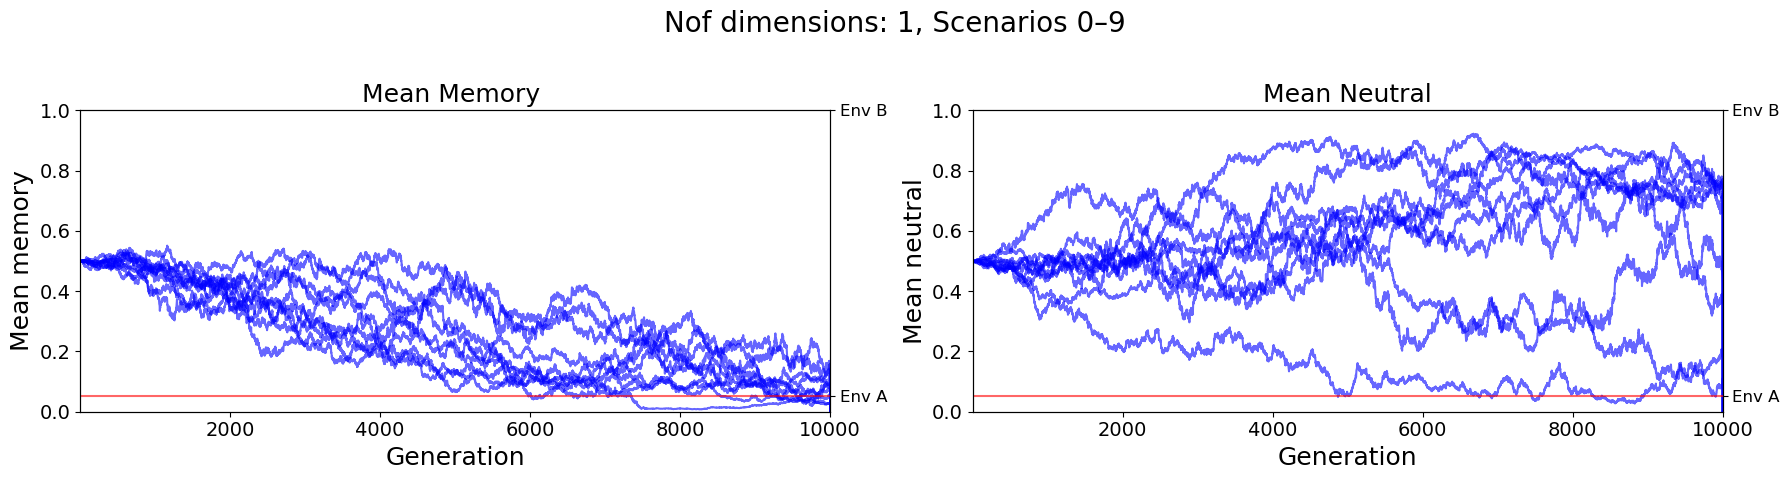

In [13]:

nof_dims=1
start = 0
stop = 5
text_size=12
gens = np.arange(1, maxgen +1 )   #Proper x-axis
# Create figure
fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharex=True)

meanmemory_p = concatenated_results_epi['meanmemory_p']
meanneutral_p = concatenated_results_epi['meanneutral_p']
stdmemory_p = concatenated_results_epi['stdmemory_p']
stdneutral_p = concatenated_results_epi['stdneutral_p']
mean_phenotype = concatenated_results_epi['mean_phenotype']

    # Loop over scenarios
for i in range(start, nof_scenarios):

        ax[0].plot(gens,meanmemory_p[i, :], color='blue', alpha=0.6)
        ax[1].plot(gens,meanneutral_p[i, :], color='blue', alpha=0.6)

env_optima =  Env[0, :]
# Axis formatting
ax[0].set_title("Mean Memory ", fontsize=18)
ax2 = ax[0].twinx()
ax2.plot(gens, env_optima, color='red', alpha = 0.6)
ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
ax[0].set_ylabel("Mean memory", fontsize=18)
ax[0].set_xlabel("Generation",  fontsize=18)
ax[0].set_xlim(1, maxgen)
ax[0].set_ylim(0, 1)

ax[1].set_title("Mean Neutral", fontsize=18)
ax2 = ax[1].twinx()
ax2.plot(gens, env_optima, color='red', alpha = 0.6)
ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
ax[1].set_ylabel("Mean neutral",  fontsize=18)
ax[1].set_xlabel("Generation", fontsize=18)
ax[1].set_xlim(1, maxgen)
ax[1].set_ylim(0, 1)
ax[0].tick_params(axis='both', labelsize=14)
ax[1].tick_params(axis='both', labelsize=14)
    
fig.suptitle(f"Nof dimensions: {nof_dims}, Scenarios {start}–{nof_scenarios - 1}", fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Sudden change

In [116]:
#Collect keys of all the list objects 
keys = list(results_array[0].keys())

concatenated_results_epi = {}


for k in keys:
        concatenated_results_epi[k] = np.vstack([r[k] for r in results_array])

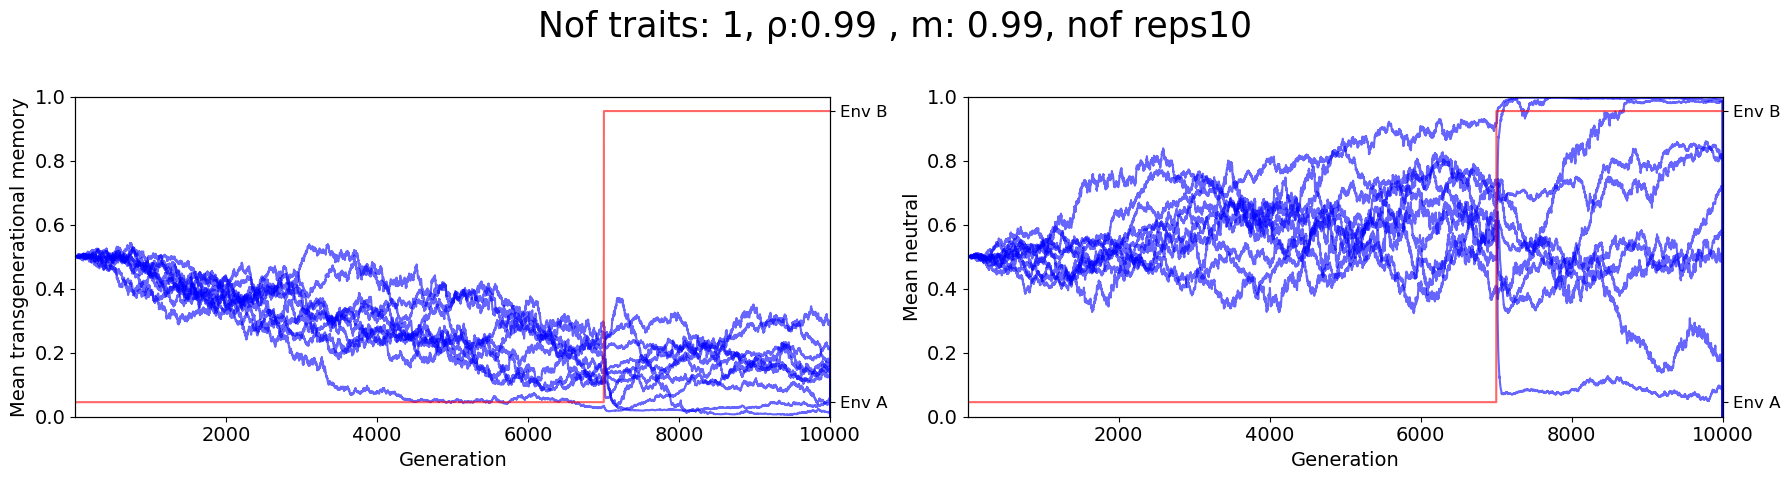

In [117]:

nof_dims=1
start = 0
text_size=12

# Create figure
fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharex=True)

meanmemory_p = concatenated_results_epi['meanmemory_p']
meanneutral_p = concatenated_results_epi['meanneutral_p']
stdmemory_p = concatenated_results_epi['stdmemory_p']
stdneutral_p = concatenated_results_epi['stdneutral_p']
mean_phenotype = concatenated_results_epi['mean_phenotype']
gens = np.arange(1, maxgen +1 )   #Proper x-axis
    # Loop over scenarios
for i in range(start, nof_scenarios):

        ax[0].plot(meanmemory_p[i, :], color='blue', alpha=0.6)
        ax[1].plot(meanneutral_p[i, :], color='blue', alpha=0.6)

env_optima =  Env[0, :]
# Axis formatting
#ax[0].set_title("Mean Memory ", fontsize=18)
ax2 = ax[0].twinx()
ax2.plot(gens, env_optima, color='red', alpha = 0.6)
ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
ax[0].set_ylabel("Mean transgenerational memory", fontsize=14)
ax[0].set_xlabel("Generation",  fontsize=14)
ax[0].set_xlim(1, maxgen)
ax[0].set_ylim(0, 1)

#ax[1].set_title("Mean Neutral", fontsize=18)
ax2 = ax[1].twinx()
ax2.plot(gens, env_optima, color='red', alpha = 0.6)
ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
ax[1].set_ylabel("Mean neutral",  fontsize=14)
ax[1].set_xlabel("Generation", fontsize=14)
ax[1].set_xlim(1, maxgen)
ax[1].set_ylim(0, 1)
ax[0].tick_params(axis='both', labelsize=14)
ax[1].tick_params(axis='both', labelsize=14)
    
    
fig.suptitle(f"Nof traits: {nof_dims}, ρ:0.99 , m: 0.99, nof reps{n_reps}", fontsize=25)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

#### Stochastic env

In [9]:
#Collect keys of all the list objects 
keys = list(results_array_stoch[0].keys())

concatenated_results_epi_stoch = {}


for k in keys:
        concatenated_results_epi_stoch[k] = np.vstack([r[k] for r in results_array_stoch])


In [19]:
env_optima =  Env_stoch[0, :4]
Env_stoch.shape[0]

20

IndexError: index 20 is out of bounds for axis 0 with size 20

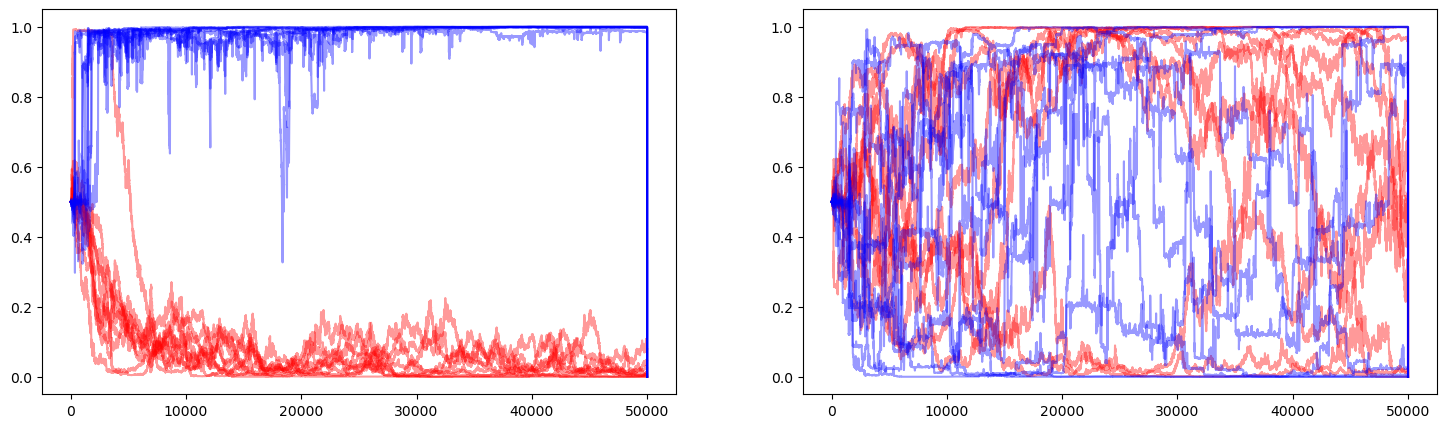

In [10]:
nof_dims = 1
start = 0
text_size = 12

fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharex=True)

gens = np.arange(1, maxgen + 1)

meanmemory_p = concatenated_results_epi_stoch['meanmemory_p']
meanneutral_p = concatenated_results_epi_stoch['meanneutral_p']
stdmemory_p = concatenated_results_epi_stoch['stdmemory_p']
stdneutral_p = concatenated_results_epi_stoch['stdneutral_p']

rho_val_0, m_val_0 = 0.8, 0.99
rho_val_1, m_val_1 = 0.9,0.97
rho_val_2, m_val_2 = 0.99, 0.85


# First 10 reps in red
for i in range(start, 10):
    ax[0].plot(gens, meanmemory_p[i, :], color='red', alpha=0.4)
    ax[1].plot(gens, meanneutral_p[i, :], color='red', alpha=0.4)

# Then add ONE styled line for the legend in red
ax[0].plot([], [], color='red', alpha=1.0, label=f'ρ = {rho_val_0}, m = {m_val_0}')
ax[1].plot([], [], color='red', alpha=1.0, label=f'ρ = {rho_val_0}, m = {m_val_0}')


# Next 10 reps in blue
for i in range(10, 20):
    ax[0].plot(gens, meanmemory_p[i, :], color='blue', alpha=0.4)
    ax[1].plot(gens, meanneutral_p[i, :], color='blue', alpha=0.4)
    
# Then add ONE styled line for the legend in blue
ax[0].plot([], [], color='blue', alpha=1.0, label=f'ρ = {rho_val_1}, m = {m_val_1}')
ax[1].plot([], [], color='blue', alpha=1.0, label=f'ρ = {rho_val_1}, m = {m_val_1}')

# Next 10 reps in blue
for i in range(20, 30):
    ax[0].plot(gens, meanmemory_p[i, :], color='green', alpha=0.4)
    ax[1].plot(gens, meanneutral_p[i, :], color='green', alpha=0.4)


# Then add ONE styled line for the legend in blue
ax[0].plot([], [], color='green', alpha=1.0, label=f'ρ = {rho_val_2}, m = {m_val_2}')
ax[1].plot([], [], color='green', alpha=1.0, label=f'ρ = {rho_val_2}, m = {m_val_2}')


# Axis formatting
ax[0].set_ylabel("Mean Transgenerational Memory", fontsize=13)
ax[0].set_xlabel("Generation", fontsize=14)
ax[0].set_xlim(1, 10000)
ax[0].set_ylim(0, 1)

ax[0].legend(
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    frameon=False
)

ax[1].set_ylabel("Mean neutral", fontsize=13)
ax[1].set_xlabel("Generation", fontsize=14)
ax[1].set_xlim(1, 10000)
ax[1].set_ylim(0, 1)

ax[0].tick_params(axis='both', labelsize=14)
ax[1].tick_params(axis='both', labelsize=14)

fig.suptitle(f"No. traits: {nof_dims}, no. reps: {n_reps}", fontsize=17)

# Legend from ax[0]; you can also use ax[1] if you prefer
ax[1].legend(
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    frameon=False
)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharex=True)


In [40]:
with open('gens50000_dims30_mutrate0.001_reps10_env3.pkl', 'wb') as f:
    pickle.dump(concatenated_results_epi_stoch, f, protocol=pickle.HIGHEST_PROTOCOL)

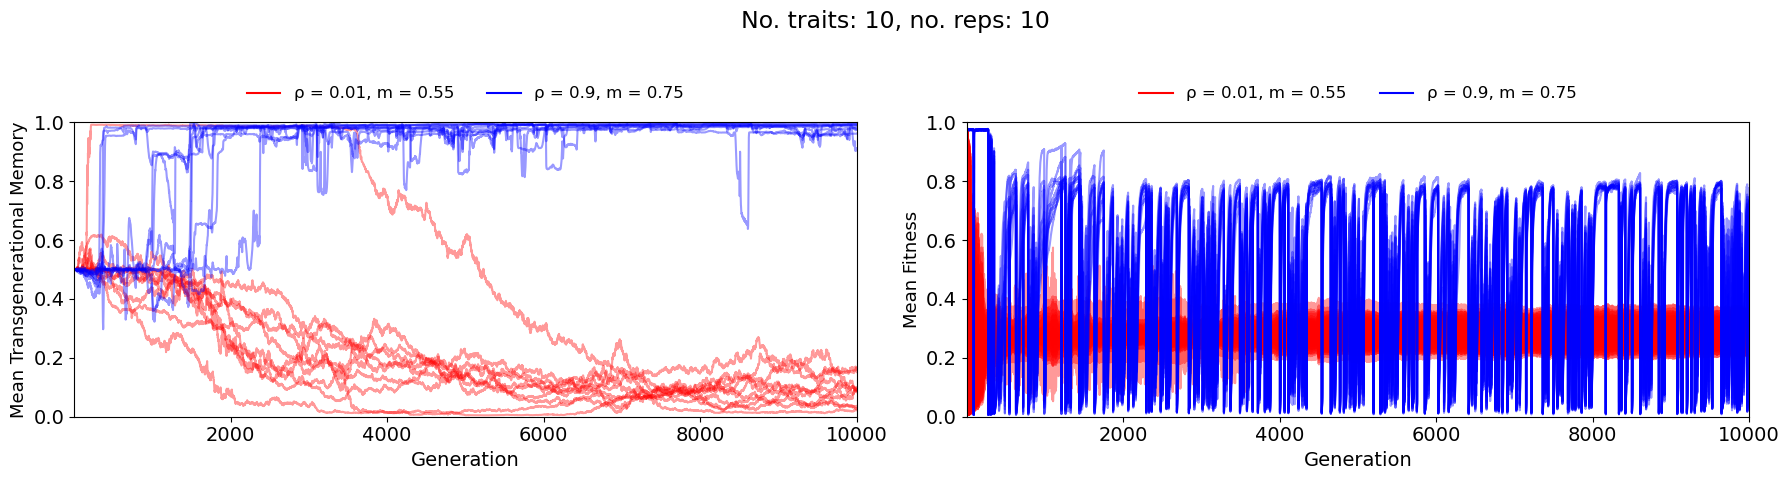

In [18]:
nof_dims = 10
start = 0
text_size = 12

fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharex=True)

gens = np.arange(1, maxgen + 1)

meanmemory_p = concatenated_results_epi_stoch['meanmemory_p']
fitness = concatenated_results_epi_stoch['meanw']

rho_val_0 =0.01
m_val_0 =0.55
# First create single scenario,
rho_val_1 =0.9
m_val_1 =0.75


# First 10 reps in red
for i in range(start, 10):
    ax[0].plot(gens, meanmemory_p[i, :], color='red', alpha=0.4)
    ax[1].plot(gens, fitness[i, :], color='red', alpha=0.4)

# Then add ONE styled line for the legend in red
ax[0].plot([], [], color='red', alpha=1.0, label=f'ρ = {rho_val_0}, m = {m_val_0}')
ax[1].plot([], [], color='red', alpha=1.0, label=f'ρ = {rho_val_0}, m = {m_val_0}')


# Next 10 reps in blue
for i in range(10, 20):
    ax[0].plot(gens, meanmemory_p[i, :], color='blue', alpha=0.4)
    ax[1].plot(gens, fitness[i, :], color='blue', alpha=0.4)

# Then add ONE styled line for the legend in red
ax[0].plot([], [], color='blue', alpha=1.0, label=f'ρ = {rho_val_1}, m = {m_val_1}')
ax[1].plot([], [], color='blue', alpha=1.0, label=f'ρ = {rho_val_1}, m = {m_val_1}')


# Axis formatting
ax[0].set_ylabel("Mean Transgenerational Memory", fontsize=13)
ax[0].set_xlabel("Generation", fontsize=14)
ax[0].set_xlim(1, 10000)
ax[0].set_ylim(0, 1)

ax[0].legend(
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    frameon=False
)

ax[1].set_ylabel("Mean Fitness", fontsize=13)
ax[1].set_xlabel("Generation", fontsize=14)
ax[1].set_xlim(1, 10000)
ax[1].set_ylim(0, 1)

ax[0].tick_params(axis='both', labelsize=14)
ax[1].tick_params(axis='both', labelsize=14)

fig.suptitle(f"No. traits: {nof_dims}, no. reps: {n_reps}", fontsize=17)

# Legend from ax[0]; you can also use ax[1] if you prefer
ax[1].legend(
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    frameon=False
)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()



### More plot code

In [ ]:
nof_dims = 2
start = 0
text_size = 12

fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharex=True)

gens = np.arange(1, maxgen + 1)

meanmemory_p = concatenated_results_epi_stoch['meanmemory_p']
fitness = concatenated_results_epi_stoch['meanw']
phenotype = concatenated_results_epi_stoch['mean_phenotype']  # Assuming this exists



# First 10 reps (ρ=0.01, m=0.55) in red
for i in range(start, 10):
    ax[0].plot(gens, meanmemory_p[i, :], color='red', alpha=0.4)
    ax[1].plot(gens, fitness[i, :], color='red', alpha=0.4)
    ax[2].plot(gens, phenotype[i, :], color='red', alpha=0.4)

# Legend line for first param
#for j, a in enumerate(ax):
ax[1].plot([], [], color='red', alpha=1.0, label=f'ρ = {rho_val_0}, m = {m_val_0}')

# Next 10 reps (ρ=0.9, m=0.75) in blue
for i in range(10, 20):
    ax[0].plot(gens, meanmemory_p[i, :], color='blue', alpha=0.4)
    ax[1].plot(gens, fitness[i, :], color='blue', alpha=0.4)
    ax[2].plot(gens, phenotype[i, :], color='blue', alpha=0.4)

# Legend line for second param
#for j, a in enumerate(ax):
ax[1].plot([], [], color='blue', alpha=1.0, label=f'ρ = {rho_val_1}, m = {m_val_1}')

xlim = 500
# Formatting each subplot
ax[0].set_ylabel("Mean Transgenerational\nMemory", fontsize=13)
ax[0].set_title("Memory Evolution", fontsize=14)
ax[0].set_ylim(0, 1)
ax[0].set_xlim(0, xlim)  # Adjust if needed

ax[1].set_ylabel("Mean Fitness", fontsize=13)
ax[1].set_title("Fitness Evolution", fontsize=14)
ax[1].set_ylim(0, 1)
ax[1].set_xlim(0, xlim)  # Adjust if needed

ax[2].set_ylabel("Mean Phenotype", fontsize=13)
ax[2].set_title("Phenotype Evolution", fontsize=14)
ax[2].set_ylim(-0.2, 1.2)  # Adjust if needed
ax[2].set_xlim(0, xlim)  # Adjust if needed

# Common x-axis
for a in ax:
    a.set_xlabel("Generation", fontsize=14)
    a.set_xlim(1, xlim)
    a.tick_params(axis='both', labelsize=14)
    a.legend(ncol=2, fontsize=16, bbox_to_anchor=(0.5, 1.1), loc="lower center", frameon=False)

fig.suptitle(f"No. traits: {nof_dims}, no. reps: {n_reps}", fontsize=17)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


#### Optionally plot for individual compariosn

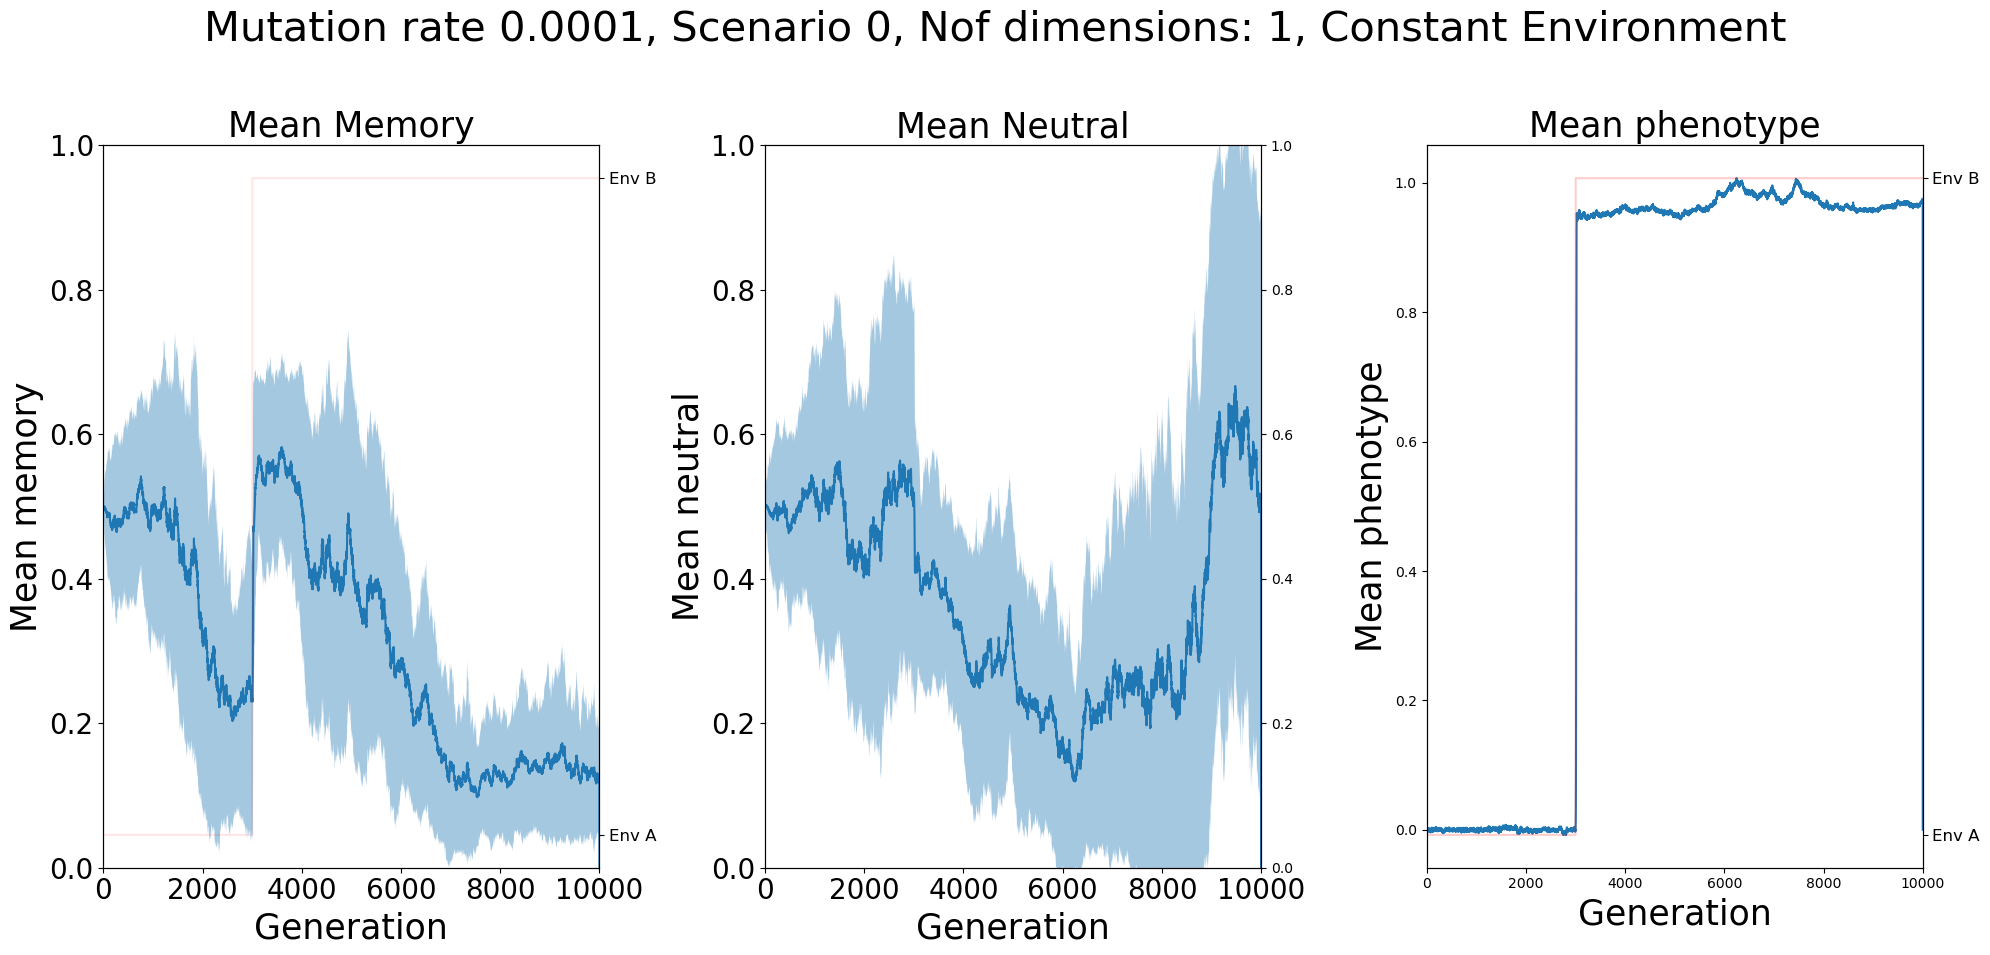

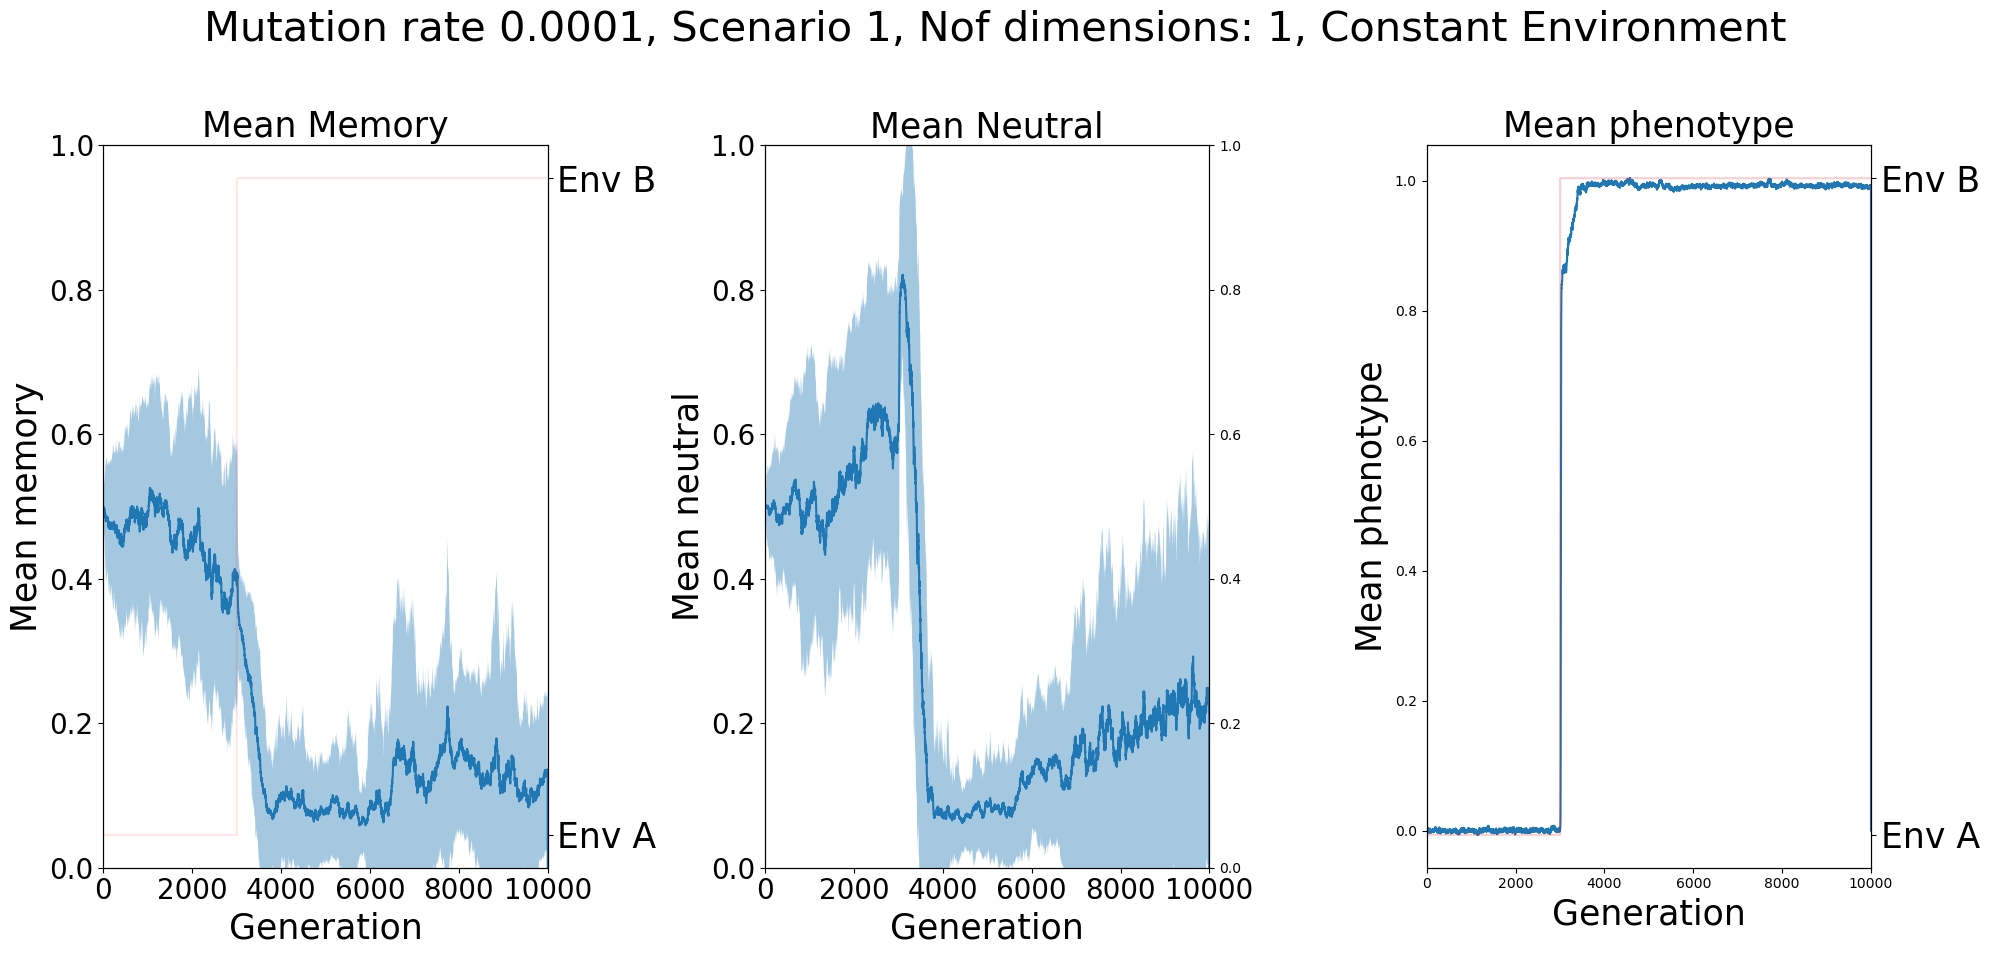

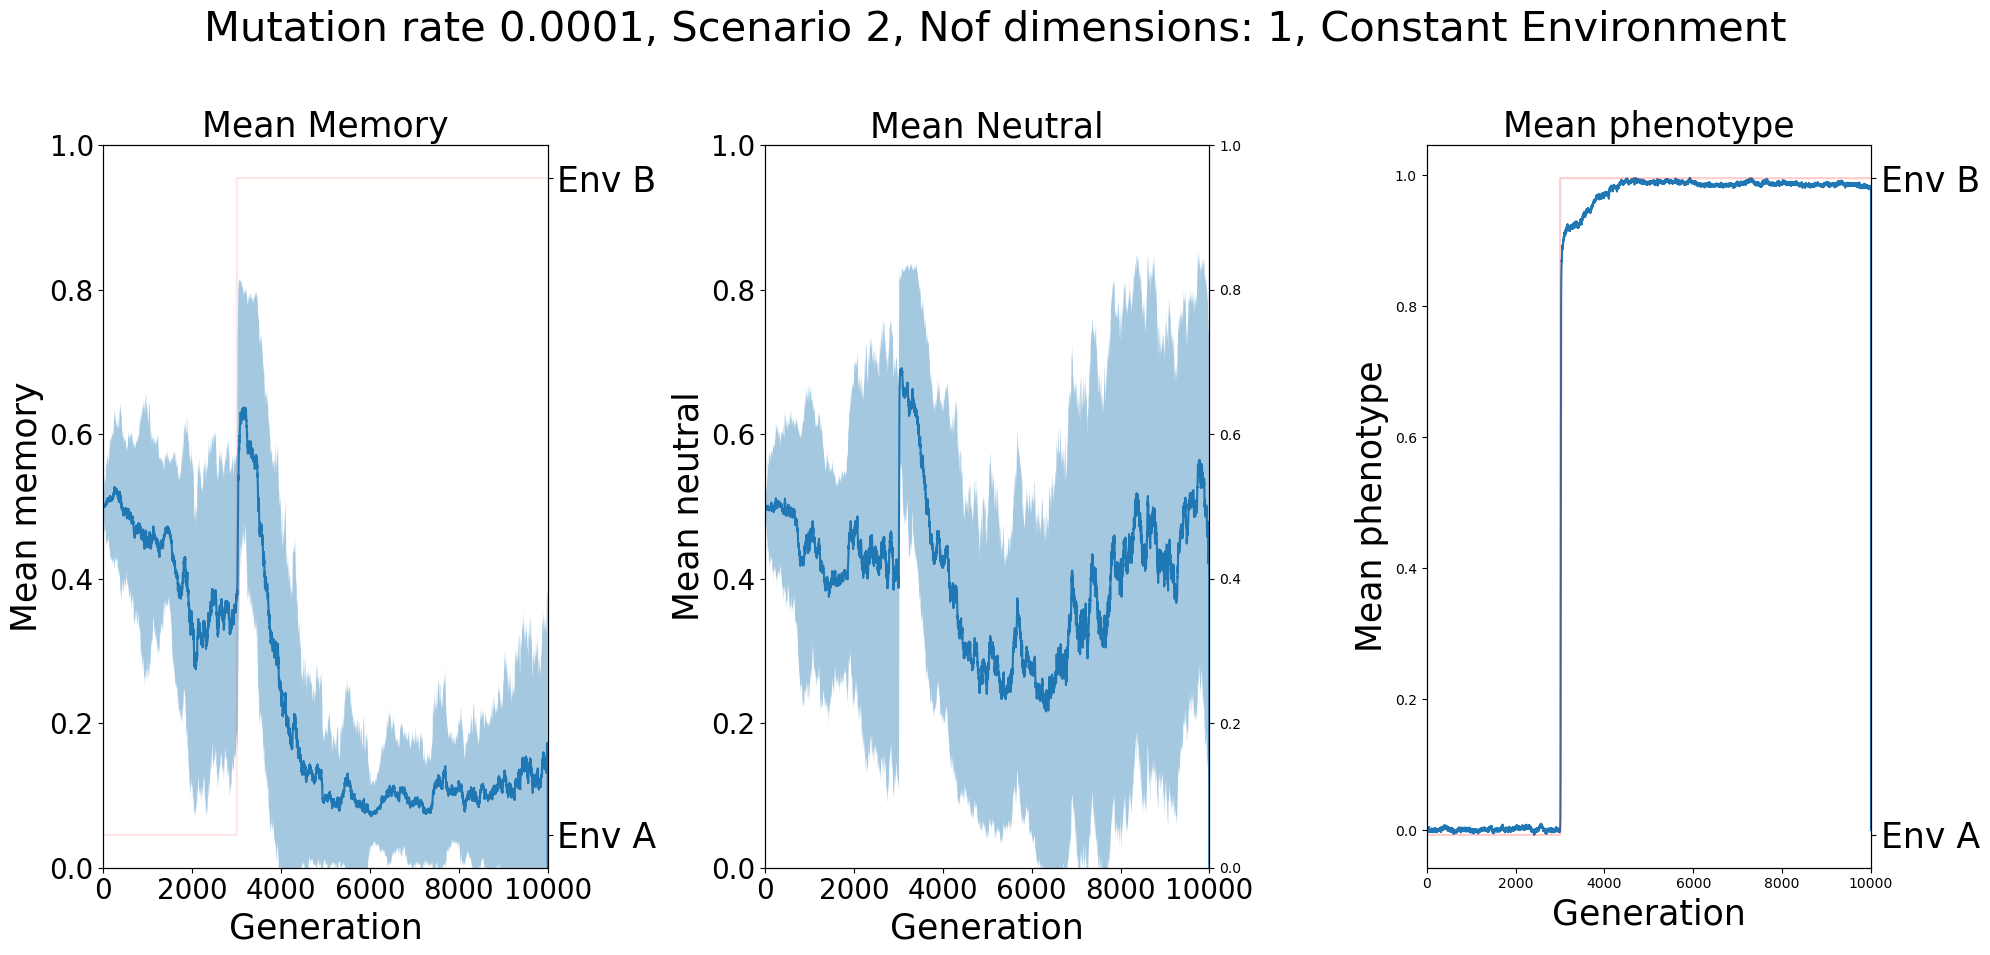

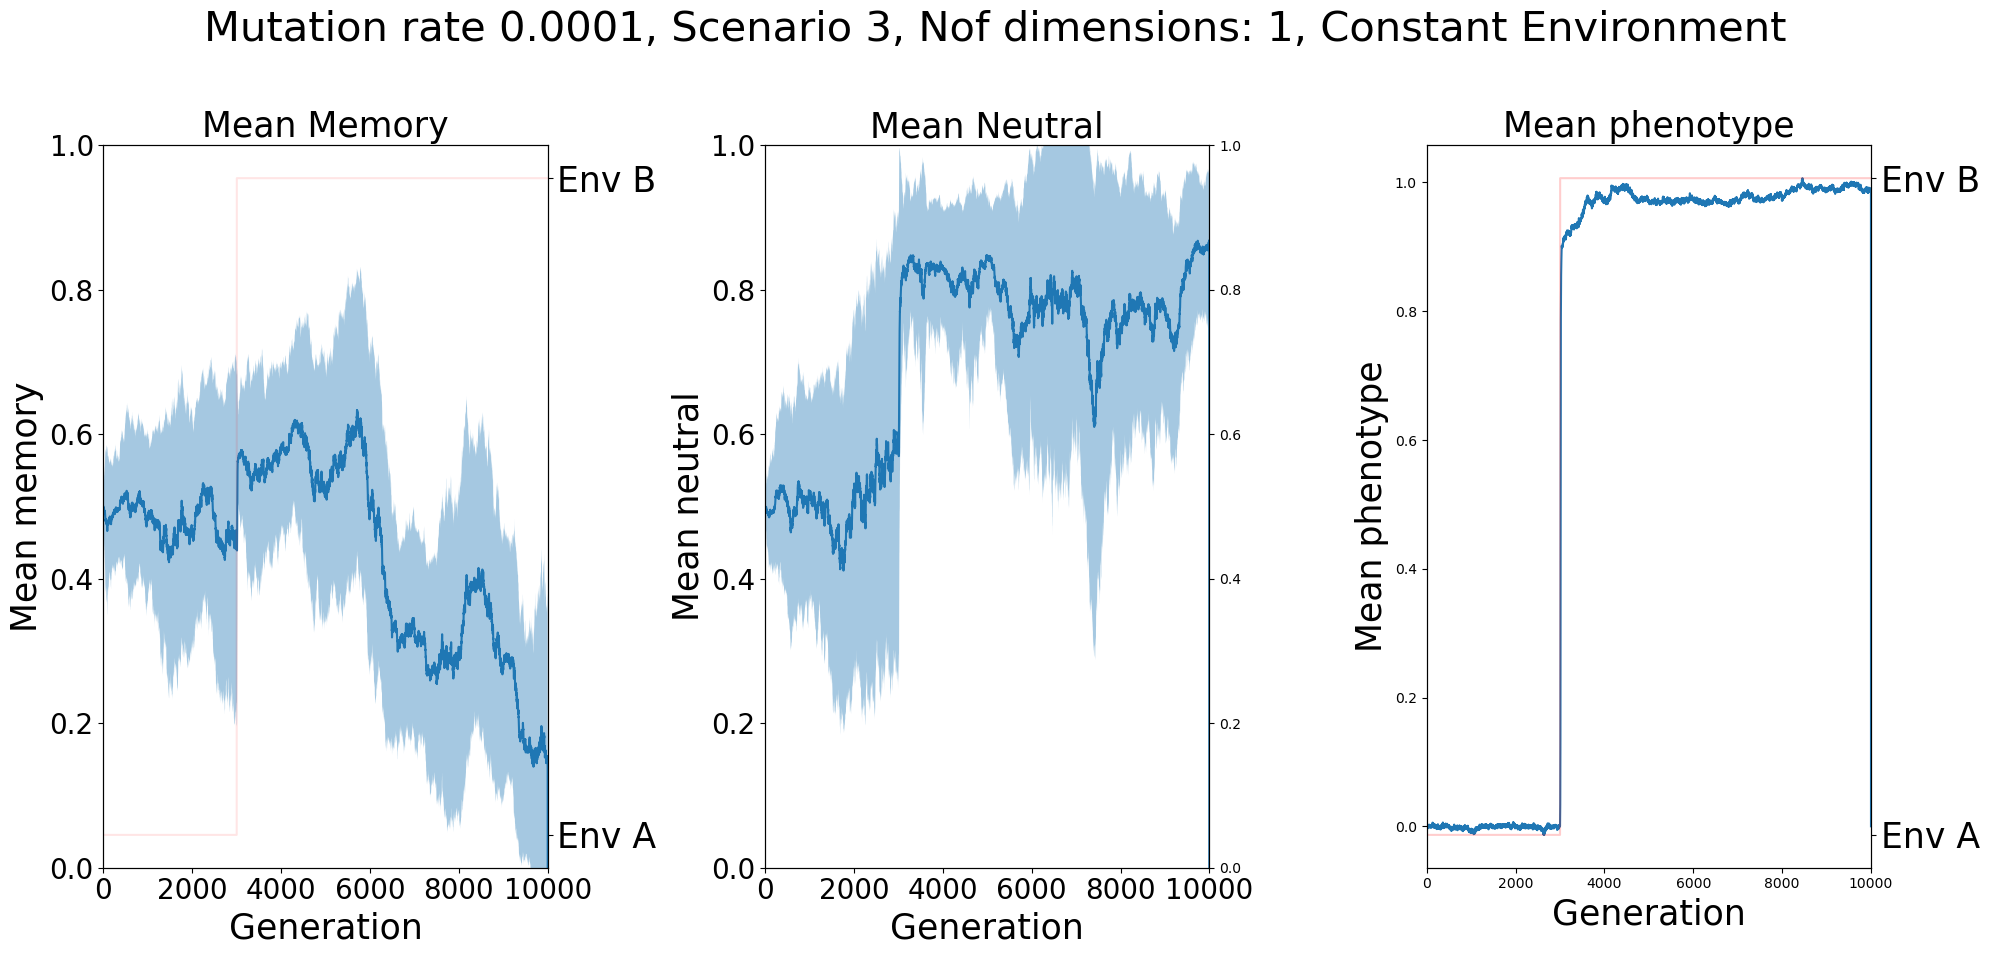

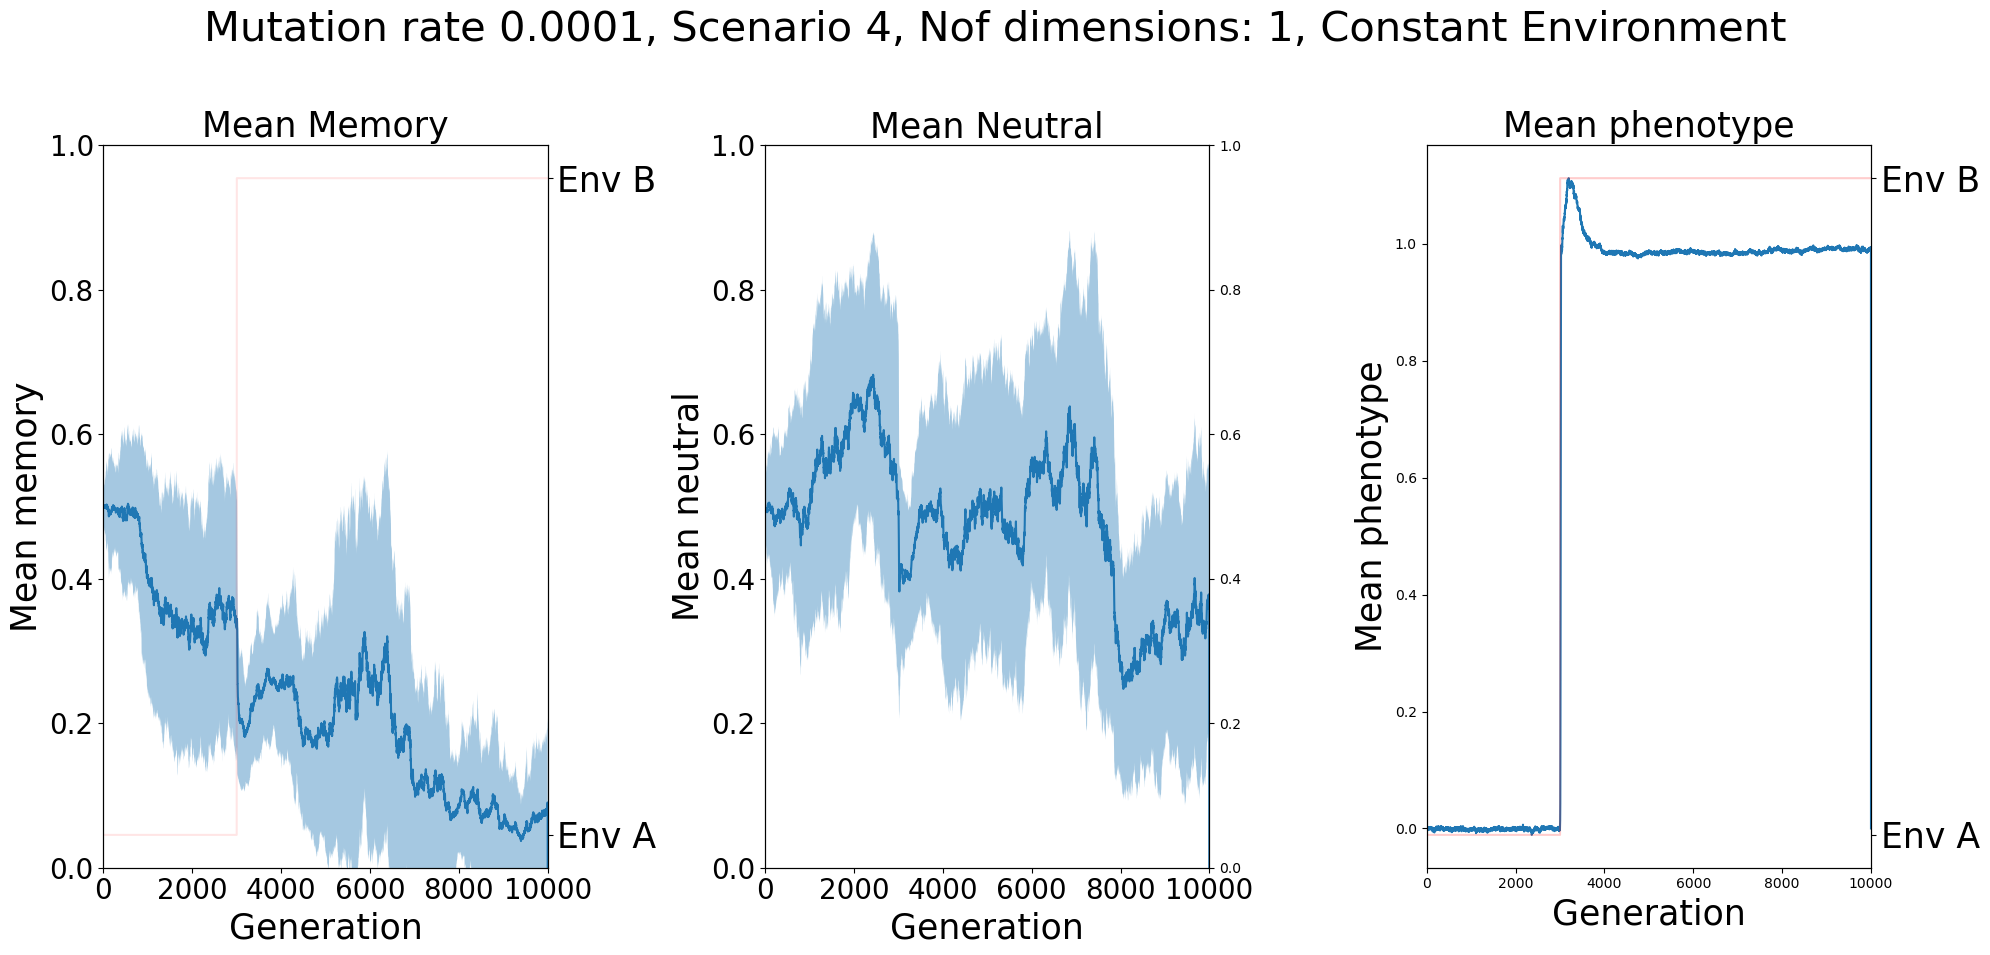

In [46]:

nof_dims=1
start = 0
stop = 5
text_size=12

for i in range(start, stop):
    
    clean_data_env_optima =  Env[i, :]
    
    meanmemory_p = concatenated_results_epi['meanmemory_p'][i, :]
    meanneutral_p = concatenated_results_epi['meanneutral_p'][i, :]
    stdmemory_p = concatenated_results_epi['stdmemory_p'][i, :]
    stdneutral_p = concatenated_results_epi['stdneutral_p'][i, :]
    mean_phenotype = concatenated_results_epi['mean_phenotype'][i, :]

    concatenated_results = {}

    # Extract variables

    maxgen = meanmemory_p.shape[0]
    gens = np.arange(1, maxgen +1 )   #Proper x-axis

    # Create figure once (outside loop)
    fig, ax = plt.subplots(1, 3, figsize=(20, 10), sharex=True)
    ax2 = ax[0].twinx()


    # Left plot: mean memory
    ax[0].plot(gens, meanmemory_p)
    ax[0].fill_between(gens, meanmemory_p - stdmemory_p, 
                            meanmemory_p + stdmemory_p, alpha=0.4 )
    ax2.plot(gens, clean_data_env_optima, color='red',  alpha = 0.1)
    ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)
    ax2 = ax[1].twinx()

    # Right plot: mean neutral
    ax[1].plot(meanneutral_p)
    ax[1].fill_between(gens, meanneutral_p - stdneutral_p, 
                            meanneutral_p + stdneutral_p, alpha=0.4 )
    ax2 = ax[2].twinx()
    ax2.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    ax2.set_yticks([0, 1], ["Env A","Env B"], fontsize =text_size)

    # Add labels, limits, and legends once
    text_size = 25
    axis_size= 20
    
    ax[0].set_title("Mean Memory", fontsize =text_size)
    ax[0].set_ylabel("Mean memory", fontsize =text_size)
    ax[0].set_xlabel("Generation", fontsize =text_size)
    ax[0].set_xlim(1, maxgen)
    ax[0].set_ylim(0, 1)

    ax[1].set_title("Mean Neutral", fontsize =text_size)
    ax[1].set_ylabel("Mean neutral", fontsize =text_size)
        
    ax[1].set_xlabel("Generation", fontsize =text_size)
    ax[1].set_xlim(1, maxgen)
    ax[1].set_ylim(0, 1)
    ax[0].tick_params(axis='both', labelsize=axis_size)
    ax[1].tick_params(axis='both', labelsize=axis_size)
    
    ax[2].plot(mean_phenotype)
    ax[2].set_title("Mean phenotype", fontsize =text_size)
    ax[2].set_ylabel("Mean phenotype", fontsize =text_size)
    ax[2].set_xlabel("Generation", fontsize =text_size)
    ax[2].set_xlim(1, maxgen)
    ax[2].set_xlim(0, 10000)
    ax2.plot(gens, clean_data_env_optima, color='red', alpha = 0.1)
    fig.suptitle(f"Mutation rate 0.0001, Scenario {i}, Nof dimensions: {nof_dims}, Constant Environment", fontsize=30)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

#### Heatmaps with seed

In [3]:
#for epi


folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_30_30_envs/1D_constant env/with_seed/epi")

epi_obj = {}

for path in folder.glob("*.pkl"):
    print(path)

    # extract dimension from filename
    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))
        with open(path, "rb") as file:
            results_array_epi = pickle.load(file)
        
        epi_obj[f"epi_{dim}"] = results_array_epi

print(epi_obj.keys())

folder = Path("/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_30_30_envs/1D_constant env/with_seed/onlygen")

onlygen_obj = {}

for path in folder.glob("*.pkl"):
    print(path)

    match = re.search(r"dims(\d+)", path.stem)
    if match:
        dim = int(match.group(1))
        with open(path, "rb") as file:
            results_array_gen = pickle.load(file)
        
        onlygen_obj[f"gen_{dim}"] = results_array_gen

print(onlygen_obj.keys())

dims=[1]

/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_30_30_envs/1D_constant env/with_seed/epi/rhos100_ms100_gens10000_dims1_mutrate0.001.pkl
dict_keys(['epi_1'])
/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/results/new_results/finegrain_30_30_envs/1D_constant env/with_seed/onlygen/rhos100_ms100_gens10000_dims1__mutrate0.001_onlygen.pkl
dict_keys(['gen_1'])


In [4]:
epi_obj[f"epi_1"][0].keys()

dict_keys(['maxgen_popsize', 'rho_m_alpha_beta', 'meanw', 'meanmemory_g', 'meanmemory_p', 'meanneutral_g', 'meanneutral_p', 'mean_geno', 'std_memory_p', 'std_neutral_p'])

In [5]:
for i in dims:
    
    concat_epi = epi_obj[f"epi_{i}"]
    concat_gen = onlygen_obj[f"gen_{i}"]   # adjust key if needed
    
    keys = list(concat_epi[0].keys())

    concatenated_results_epi = {}
    concatenated_results_gen = {}

    for k in keys:
            concatenated_results_epi[k] = np.vstack([r[k] for r in concat_epi])
            
    for k in keys:
            concatenated_results_gen[k] = np.vstack([r[k] for r in concat_gen])
            
    df_epi = pd.DataFrame({
        
    'rho': concatenated_results_epi['rho_m_alpha_beta'][:,0],
    'm': concatenated_results_epi['rho_m_alpha_beta'][:,1],
    'fitness':np.mean(concatenated_results_epi['meanw'][:,-50:], axis=1),
    'epi_mem_p': np.mean(concatenated_results_epi['meanmemory_p'][:,-50:], axis=1),
    'neutral_trait_p' : np.mean(concatenated_results_epi['meanneutral_p'][:,-50:], axis=1 ),
    'stdw': np.mean(concatenated_results_epi['stdw'][:,:-100], axis=1),
    'mean_phenotype' : np.mean(concatenated_results_epi['mean_phenotype'][:,:-50], axis=1 ),
    'std_phenotype' : np.mean(concatenated_results_epi['std_phenotype'][:,:-50], axis=1 ),
    
    })
    
    df_gen = pd.DataFrame({
            
        'rho': concatenated_results_gen['rho_m_alpha_beta'][:,0],
        'm': concatenated_results_gen['rho_m_alpha_beta'][:,1],
        'fitness':np.mean(concatenated_results_gen['meanw'][:,-50:], axis=1),
        'stdw':np.mean(concatenated_results_gen['stdw'][:,-50:], axis=1),
        'mean_phenotype' : np.mean(concatenated_results_gen['mean_phenotype'][:,:-50], axis=1 ),
        'std_phenotype' : np.mean(concatenated_results_gen['std_phenotype'][:,:-50], axis=1 )
        })

    fig, ax = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        f"Fitness and Evolved Transgenerational memory strength, no. of dimensions {i}",
        fontsize=16
    )
    
    fig.subplots_adjust(top=0.90)

    cmap1 = plt.cm.copper.copy()
    cmap1.set_bad(color='gray')

    cmap2 = plt.cm.viridis.copy()
    cmap2.set_bad(color='gray')
    
    norm = mcolors.Normalize(vmin=0, vmax=1)
    
    # --- (0,0) fitness ---
    pivoted_fitness = df_epi.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    pcm1 = ax[0,0].pcolormesh(
        pivoted_fitness.columns,
        pivoted_fitness.index,
        pivoted_fitness.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    fig.colorbar(pcm1, ax=ax[0,0],
                 label='Fitness (W) with Transgenerational memory',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0,0].set_title(r'Fitness with Transgenerational-memory')
    ax[0,0].set_ylabel('m')
    ax[0,0].set_xlabel('rho')

    # --- (0,1) genetic fitness ---
    pivoted_gen = df_gen.pivot_table(
        index='m', columns='rho', values='fitness'
    ).sort_index().sort_index(axis=1)

    pcm2 = ax[0,1].pcolormesh(
        pivoted_gen.columns,
        pivoted_gen.index,
        pivoted_gen.values,
        cmap=cmap1, norm=norm, shading='auto'
    )
    fig.colorbar(pcm2, ax=ax[0,1],
                 label='Fitness (W) only genetics',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[0,1].set_title('Genetic fitness')
    ax[0,1].set_ylabel('m')
    ax[0,1].set_xlabel('rho')

    # --- (1,0) epimem ---
    pivoted_epi = df_epi.pivot_table(
        index='m', columns='rho', values='epi_mem_p'
    ).sort_index().sort_index(axis=1)

    pcm3 = ax[1,0].pcolormesh(
        pivoted_epi.columns,
        pivoted_epi.index,
        pivoted_epi.values,
        cmap=cmap2, norm=norm, shading='auto'
    )
    fig.colorbar(pcm3, ax=ax[1,0],
                 label='Evolved Transgenerational-memory strength',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[1,0].set_title('Transgenerational-memory')
    ax[1,0].set_ylabel('m')
    ax[1,0].set_xlabel('rho')

    # --- (1,1) neutral ---
    pivoted_neutral = df_epi.pivot_table(
        index='m', columns='rho', values='neutral_trait_p'
    ).sort_index().sort_index(axis=1)

    pcm4 = ax[1,1].pcolormesh(
        pivoted_neutral.columns,
        pivoted_neutral.index,
        pivoted_neutral.values,
        cmap=cmap2, norm=norm, shading='auto'
    )
    fig.colorbar(pcm4, ax=ax[1,1],
                 label='Neutral trait',
                 ticks=[0,0.25,0.5,0.75,1.0])

    ax[1,1].set_title('Neutral trait')
    ax[1,1].set_ylabel('m')
    ax[1,1].set_xlabel('rho')

    plt.tight_layout()
    plt.savefig(f'/home/usriniva/Desktop/Phd/Epigenetics/Simulations/New_Hanna_eqns/Evolve_Transgenerational_memory/Figures/finegrain_dims/Delta_Fitness_Epi-Gen_dim{i}_wmemory')
    plt.show()


: 